# WFP Data Exploration

**Goal:** Explore the real market-price data from the World Bank/WFP source. 
We want to understand price distributions, inflation trends over time, seasonality, and variations across regions and products.

**Prerequisites:** This notebook assumes the Parquet files (`fact_market_price.parquet`, `dim_product.parquet`, `dim_market.parquet`, `dim_region.parquet`, `dim_date.parquet`) exist in the `data/processed/` directory.

In [3]:
import sys
from pathlib import Path

# Set project root to allow importing src
sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.config.settings import settings

# Plotting style
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("Set2")
pd.set_option('display.max_columns', None)

print("Libraries loaded.")

Libraries loaded.


## 1. Load and Merge Data

We load the fact table and join the dimensions so we have human-readable names instead of just IDs.

In [4]:
# Load datasets
fact_price = pd.read_parquet(settings.data_processed_dir / "fact_market_price.parquet")
dim_product = pd.read_parquet(settings.data_processed_dir / "dim_product.parquet")
dim_wfp_market = pd.read_parquet(settings.data_processed_dir / "dim_wfp_market.parquet")
dim_region = pd.read_parquet(settings.data_processed_dir / "dim_region.parquet")
dim_date = pd.read_parquet(settings.data_processed_dir / "dim_date.parquet")

# Map original WFP region names to dim_region names.
dim_wfp_market["region_name"] = dim_wfp_market["adm1_name"]

# Merge to create a rich analysis dataframe.
df = (
    fact_price
    .merge(dim_product, on="product_id", how="left", validate="many_to_one")
    .merge(dim_wfp_market[["wfp_market_id", "market_name", "adm1_name", "adm2_name", "region_name"]],
        on="wfp_market_id", how="left", validate="many_to_one", )
    .merge(
        dim_region[["region_id", "region_name"]],
        on="region_name", how="left", validate="many_to_one",
        suffixes=("", "_dim"), )
    .merge(
        dim_date[["date_id", "date", "year", "month"]],
        on="date_id", how="left", validate="many_to_one", )
)

# Fail if any foreign key failed to resolve.
if df["market_name"].isna().any():
    raise ValueError("Some price records have no matching WFP market.")
if df["product_name"].isna().any():
    raise ValueError("Some price records have no matching product.")
if df["region_id"].isna().any():
    raise ValueError("Some WFP regions could not be matched to dim_region.")
if df["date"].isna().any():
    raise ValueError("Some price records have no matching date.")

print(f"Total price observations: {len(df):,}")
display(df.head())

Total price observations: 237,048


,wfp_market_id,product_id,date_id,price,trust,product_name,category,unit,brand,market_name,adm1_name,adm2_name,region_name,region_id,date,year,month
0,78,1,20070101,1565.01,9.5,bananas,fruit,12 KG,None,Adoumri,Nord,Bénoué,Nord,6,2007-01-01,2007,1
1,78,1,20070201,1570.90,9.5,bananas,fruit,12 KG,None,Adoumri,Nord,Bénoué,Nord,6,2007-02-01,2007,2
2,78,1,20070301,1586.09,9.5,bananas,fruit,12 KG,None,Adoumri,Nord,Bénoué,Nord,6,2007-03-01,2007,3
3,78,1,20070401,1562.13,9.5,bananas,fruit,12 KG,None,Adoumri,Nord,Bénoué,Nord,6,2007-04-01,2007,4
4,78,1,20070501,1542.27,9.5,bananas,fruit,12 KG,None,Adoumri,Nord,Bénoué,Nord,6,2007-05-01,2007,5


## 2. Data Quality and Trust

The WFP dataset includes a `trust` score (0-10). Lower scores mean the price is heavily imputed by the World Bank's models rather than directly observed.

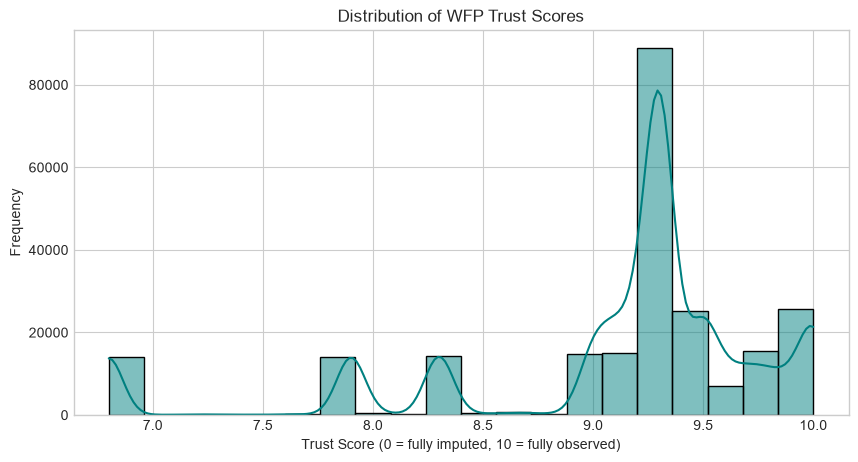

In [5]:
plt.figure(figsize=(10, 5))
sns.histplot(df['trust'].dropna(), bins=20, kde=True, color='teal')
plt.title("Distribution of WFP Trust Scores")
plt.xlabel("Trust Score (0 = fully imputed, 10 = fully observed)")
plt.ylabel("Frequency")
plt.show()

## 3. Price Distributions by Product

Prices are in local currency (XAF). Because different commodities have vastly different scales (e.g., meat vs. cassava), a log scale makes the distributions comparable.

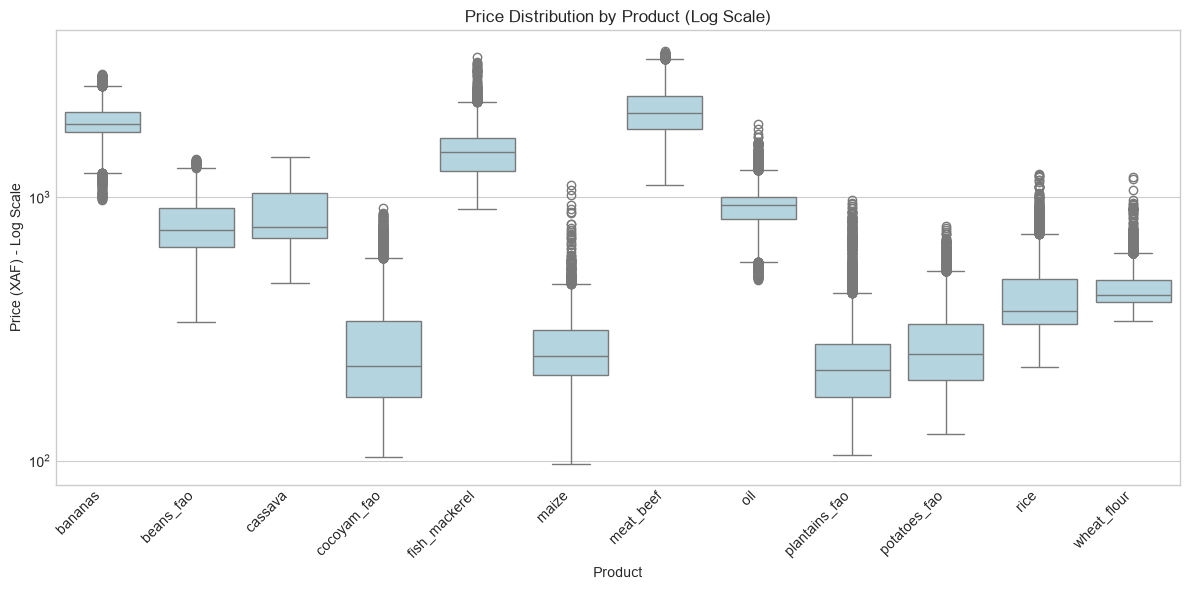

In [6]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='product_name', y='price', color='lightblue')
plt.yscale('log')
plt.xticks(rotation=45, ha='right')
plt.title("Price Distribution by Product (Log Scale)")
plt.xlabel("Product")
plt.ylabel("Price (XAF) - Log Scale")
plt.tight_layout()
plt.show()

## 4. Temporal Trends (Inflation over Time)

We plot the national average monthly price for a few key staples to see how inflation has moved over the years.

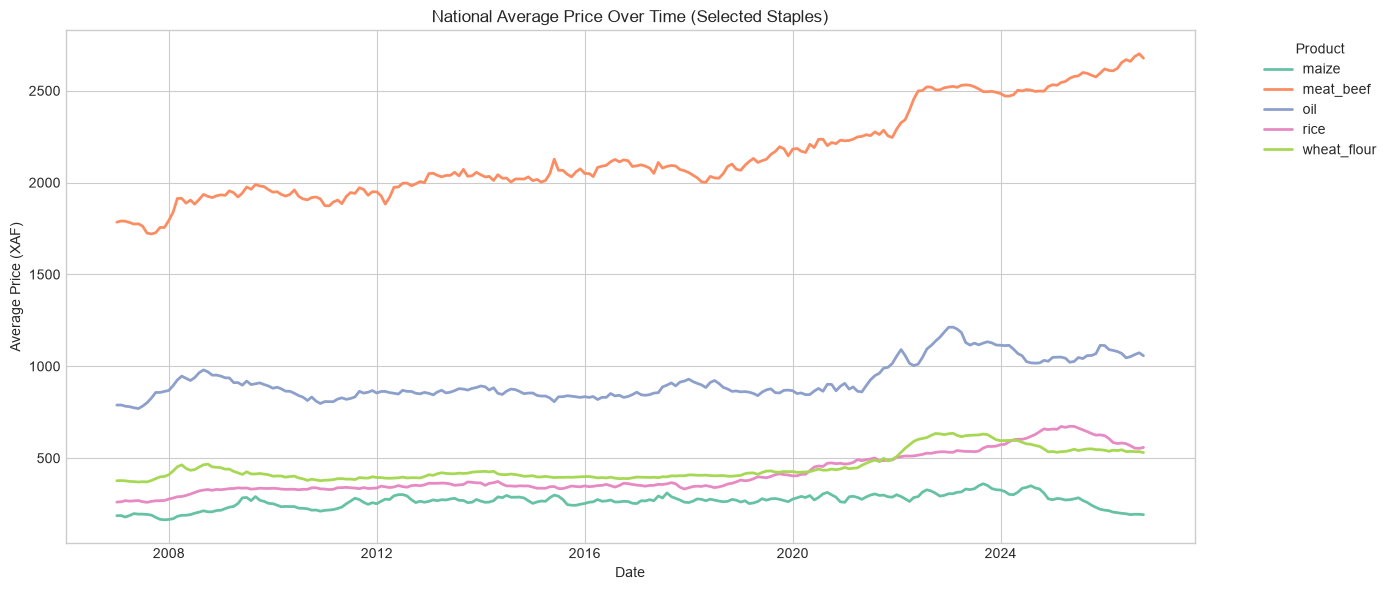

In [7]:
# Calculate national monthly average price per product
monthly_avg = df.groupby(['date', 'product_name'])['price'].mean().reset_index()

# Plot selected commodities
selected_products = ['rice', 'maize', 'wheat_flour', 'oil', 'meat_beef']
subset = monthly_avg[monthly_avg['product_name'].isin(selected_products)]

plt.figure(figsize=(14, 6))
sns.lineplot(data=subset, x='date', y='price', hue='product_name', linewidth=2)
plt.title("National Average Price Over Time (Selected Staples)")
plt.xlabel("Date")
plt.ylabel("Average Price (XAF)")
plt.legend(title="Product", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 5. Seasonality

Does the price of food fluctuate with the seasons? We look at the average price by calendar month across all years.

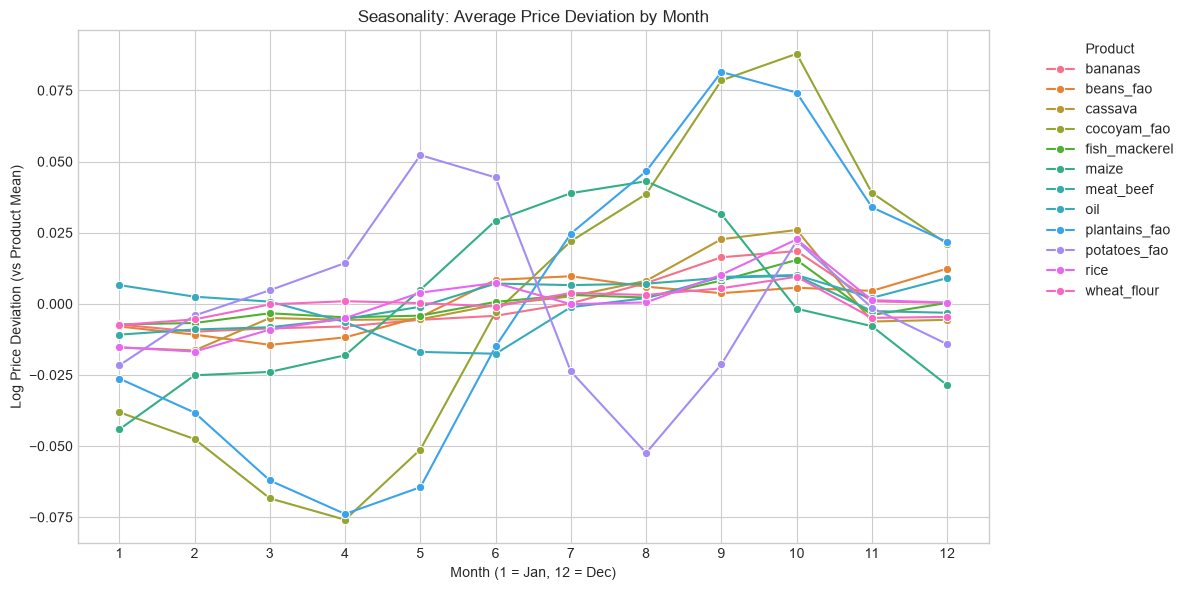

In [8]:
# Average price by month (indexed to the product's overall mean to show % variation)
df['log_price'] = np.log(df['price'])
df['price_deviation'] = df['log_price'] - df.groupby('product_name')['log_price'].transform('mean')

monthly_seasonality = df.groupby(['month', 'product_name'])['price_deviation'].mean().reset_index()

plt.figure(figsize=(12, 6))
sns.lineplot(data=monthly_seasonality, x='month', y='price_deviation', hue='product_name', marker='o')
plt.title("Seasonality: Average Price Deviation by Month")
plt.xlabel("Month (1 = Jan, 12 = Dec)")
plt.ylabel("Log Price Deviation (vs Product Mean)")
plt.xticks(range(1, 13))
plt.legend(title="Product", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 6. Regional Variations

Are prices fundamentally higher in certain regions? We calculate the median price of a staple (e.g., Rice) across the 10 regions.

C:\Users\visi\AppData\Local\Temp\ipykernel_6256\1191401863.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=region_prices, x='price', y='region_name', palette='viridis')


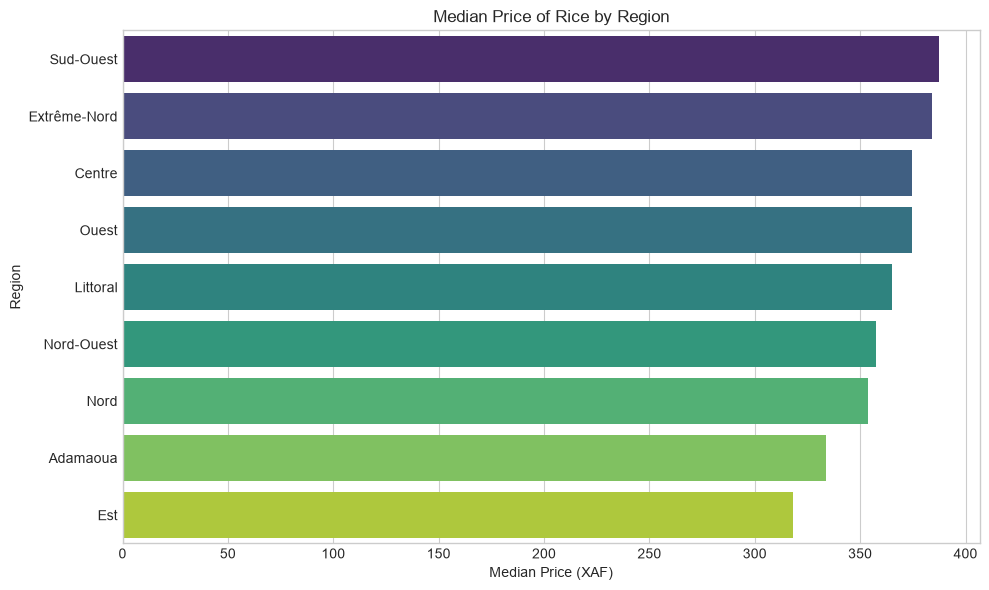

In [9]:
# Filter for rice
rice_df = df[df['product_name'] == 'rice']

# Calculate median price by region
region_prices = rice_df.groupby('region_name')['price'].median().sort_values(ascending=False).reset_index()

plt.figure(figsize=(10, 6))
sns.barplot(data=region_prices, x='price', y='region_name', palette='viridis')
plt.title("Median Price of Rice by Region")
plt.xlabel("Median Price (XAF)")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

## 7. Price Volatility

How volatile are prices? High volatility implies higher risk for inventory and supply chains. We compute the coefficient of variation (Std / Mean) for each product.

C:\Users\visi\AppData\Local\Temp\ipykernel_6256\3992509955.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=volatility, x='cv', y='product_name', palette='magma')


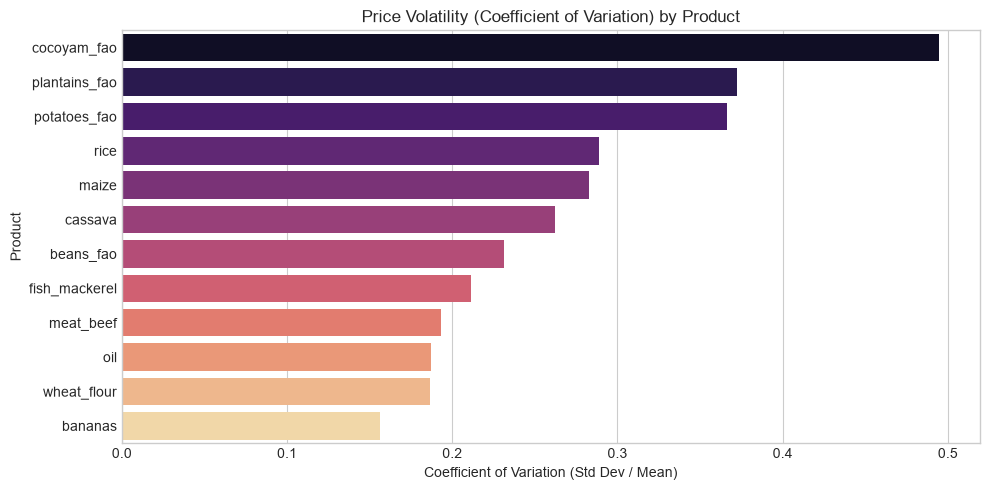

In [10]:
volatility = df.groupby('product_name')['price'].agg(['mean', 'std']).reset_index()
volatility['cv'] = volatility['std'] / volatility['mean']
volatility = volatility.sort_values('cv', ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(data=volatility, x='cv', y='product_name', palette='magma')
plt.title("Price Volatility (Coefficient of Variation) by Product")
plt.xlabel("Coefficient of Variation (Std Dev / Mean)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

## 8. Market-Level Dispersion (Spatial Variation)

Instead of looking at time series, we look at a single month to see how much prices vary across the 360 markets for a single product.

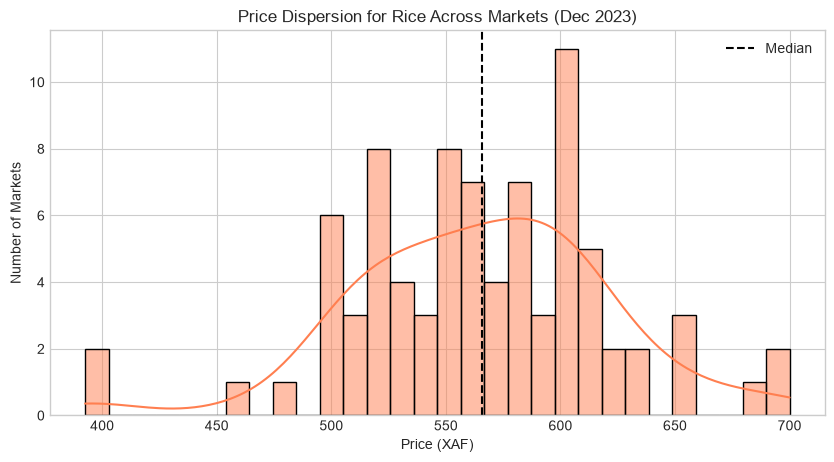

In [11]:
# Look at a recent month (e.g., Dec 2023)
snapshot = rice_df[rice_df['date'] == '2023-12-01']

if not snapshot.empty:
    plt.figure(figsize=(10, 5))
    sns.histplot(snapshot['price'], bins=30, kde=True, color='coral')
    plt.axvline(snapshot['price'].median(), color='black', linestyle='--', label='Median')
    plt.title("Price Dispersion for Rice Across Markets (Dec 2023)")
    plt.xlabel("Price (XAF)")
    plt.ylabel("Number of Markets")
    plt.legend()
    plt.show()
else:
    print("No data found for Dec 2023.")